# Notebook 7 — Three Standard Fixes, and Which One Your Problem Actually Needs

### Course roadmap

**Part I — the data** · 1. What an action really is · 2. Anatomy of a demonstration
**Part II — simulation** · 3. Physics from scratch · 4. The robot model · 5. System identification
**Part III — learning policies** · 6. Behavior cloning · **7. Fixing it, honestly** · 8. RL in simulation
**Part IV — reality** · 9. Domain randomization · 10. `lerobot` end to end

---

### The real-world problem

> **Your BC policy drifts. The literature offers you three fixes. Two of them
> will waste your week.**

Notebook 6 produced a policy with excellent held-out action error and
catastrophic closed-loop drift. The standard toolkit for that situation:

| Fix | Who uses it | What it is supposed to cure |
|---|---|---|
| **Action chunking** | ACT, π0, Diffusion Policy, GR00T | jitter from independent per-step predictions; latency |
| **Vision** | essentially every modern VLA | the policy cannot see the objects |
| **History / state stacking** | the oldest and cheapest trick | the policy cannot tell where it is in the task |

A 2026 robotics salary guide lists *"imitation-learning methods such as diffusion
policies and ACT"* as expected knowledge, so these are not academic curiosities
— they are the named tools of the trade.

The temptation is to apply all three. That is expensive: vision means decoding
video, a CNN encoder, and 20x the training time. On a real project you want to
know **which fix addresses your actual bottleneck** before you spend the week.

### This notebook's method: predict, then measure

Notebook 6 diagnosed the failure as **phase ambiguity** — the arm revisits poses
about 6 s apart that demand opposite actions, and six joint angles cannot
distinguish them. Crucially it also ruled things *out*: the policy moves at 97%
of human speed, so it is not averaging conflicting labels into paralysis, and
notebook 2 measured the dataset as unimodal.

From that diagnosis we can **predict the results before running them.** Writing
predictions down first is the only way to tell whether your mental model works,
so that is what we will do. One of the three fixes should help substantially.
One should do nothing. One should actively hurt.

If the diagnosis from notebook 6 is right, history wins and the other two do not.
If chunking or vision wins, the diagnosis was wrong and we learn that instead.

**Spoiler, because burying it would be dishonest: two of these three predictions
turned out wrong, and the thing that broke them is more useful than the thing I
was trying to show.** The sections below keep the predictions where they were
written so you can see exactly how they failed.

In [1]:
import json, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import mujoco
from huggingface_hub import hf_hub_download

torch.manual_seed(0); np.random.seed(0); torch.set_num_threads(4)
REPO, FPS = "lerobot/svla_so101_pickplace", 30
JOINTS = ["shoulder_pan", "shoulder_lift", "elbow_flex", "wrist_flex", "wrist_roll", "gripper"]

STATS = json.load(open("../artifacts/so101_stats.json"))
raw = pd.read_parquet(hf_hub_download(REPO, "data/chunk-000/file-000.parquet", repo_type="dataset"))
raw = raw.sort_values(["episode_index", "frame_index"]).reset_index(drop=True)
S = np.stack(raw["observation.state"].values).astype(np.float32)
A = np.stack(raw["action"].values).astype(np.float32)
EP = raw["episode_index"].values

s_mean = np.array(STATS["observation.state"]["mean"], np.float32)
s_std  = np.array(STATS["observation.state"]["std"],  np.float32)
a_min  = np.array(STATS["action"]["min"], np.float32)
a_max  = np.array(STATS["action"]["max"], np.float32)
norm_state    = lambda x: (x - s_mean) / s_std
norm_action   = lambda a: 2 * (a - a_min) / (a_max - a_min) - 1
denorm_action = lambda y: (y + 1) / 2 * (a_max - a_min) + a_min

TRAIN_EPS, VAL_EPS = STATS["train_episodes"], STATS["val_episodes"]

# The identified simulator from notebook 5 is our evaluation harness.
mm = mujoco.MjModel.from_xml_path("../models/so101/so101_identified.xml")
CR = mm.actuator_ctrlrange.copy()
SUB = int(round((1 / FPS) / mm.opt.timestep))
to_rad  = lambda x: CR[:, 0] + (x + 100.0) / 200.0 * (CR[:, 1] - CR[:, 0])
to_norm = lambda q: -100.0 + (q - CR[:, 0]) / (CR[:, 1] - CR[:, 0]) * 200.0

def real_episode(e):
    ed = raw[raw.episode_index == e]
    return (np.stack(ed["action"].values).astype(np.float64),
            np.stack(ed["observation.state"].values).astype(np.float64))

print(f"train {len(TRAIN_EPS)} eps | val {len(VAL_EPS)} eps | identified sim, {SUB} substeps/action")

/Users/manujmehrotra/Desktop/repository/reinforcement-learning/physical-ai/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train 40 eps | val 10 eps | identified sim, 7 substeps/action


## 2. A common evaluation harness

Every fix changes a different part of the pipeline — the input features, the
output shape, or how many actions get executed per decision. To compare them
honestly we need one harness that handles all three, reporting the same two
numbers each time: **teacher-forced error** and **closed-loop drift**.

Getting this abstraction right is most of the work in a comparison like this.
The temptation is to hand-roll each experiment, at which point you are no longer
measuring the fix, you are measuring your bookkeeping.

In [2]:
class Policy(nn.Module):
    """One policy class covering all variants.

    obs_fn : (history of states) -> feature vector      (handles state / history / vision)
    chunk  : how many future actions to predict         (1 = plain BC)
    exec_k : how many of them to execute before replanning
    """
    def __init__(self, in_dim, chunk=1, hidden=256, encoder=None, enc_dim=0):
        super().__init__()
        self.chunk = chunk
        self.encoder = encoder
        self.net = nn.Sequential(
            nn.Linear(in_dim + enc_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 6 * chunk), nn.Tanh(),
        )

    def forward(self, vec, img=None):
        if self.encoder is not None:
            vec = torch.cat([self.encoder(img), vec], dim=1)
        return self.net(vec).view(-1, self.chunk, 6)

def make_dataset(episodes, obs_fn, chunk=1, img_source=None):
    """Build (features, images, action-chunks) for the given episodes."""
    Xs, Is, Ys = [], [], []
    for e in episodes:
        mk = EP == e
        s_ep, a_ep = S[mk], norm_action(A[mk])
        idx_ep = np.where(mk)[0]
        T = len(s_ep)
        for t in range(T - chunk + 1):
            Xs.append(obs_fn([s_ep[max(0, t - k)] for k in range(obs_fn.lookback, -1, -1)]))
            Ys.append(a_ep[t:t + chunk])
            if img_source is not None:
                Is.append(img_source[idx_ep[t]])
    X = torch.tensor(np.array(Xs, np.float32))
    Y = torch.tensor(np.array(Ys, np.float32))
    I = torch.tensor(np.array(Is, np.float32))[:, None] if img_source is not None else None
    return X, I, Y

def train(net, X, Y, I=None, iters=4000, bs=256, lr=1e-3, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(net.parameters(), lr)
    for _ in range(iters):
        i = torch.randint(0, len(X), (bs,))
        opt.zero_grad()
        pred = net(X[i], I[i]) if I is not None else net(X[i])
        nn.functional.mse_loss(pred, Y[i]).backward()
        opt.step()
    return net

@torch.no_grad()
def eval_teacher_forced(net, X, Y, I=None, bs=1024):
    net.eval()
    tot, n = 0.0, 0
    for k in range(0, len(X), bs):
        pred = net(X[k:k+bs], I[k:k+bs]) if I is not None else net(X[k:k+bs])
        tot += nn.functional.mse_loss(pred, Y[k:k+bs], reduction="sum").item()
        n += Y[k:k+bs].numel()
    net.train()
    return tot / n

@torch.no_grad()
def eval_closed_loop(net, obs_fn, exec_k=1, episodes=None, img_fallback=None):
    """Let the policy drive in the identified sim. Returns mean final drift."""
    net.eval()
    drifts = []
    for e in (episodes or VAL_EPS):
        _, S_real = real_episode(e)
        d = mujoco.MjData(mm)
        d.qpos[:] = to_rad(S_real[0]); d.qvel[:] = 0.0
        mujoco.mj_forward(mm, d)
        traj = np.empty((len(S_real), 6)); hist = []
        t = 0
        while t < len(S_real):
            s = to_norm(d.qpos.copy())
            hist.append(s.astype(np.float32))
            feats = obs_fn([hist[max(0, len(hist) - 1 - k)] for k in range(obs_fn.lookback, -1, -1)])
            x = torch.tensor(feats, dtype=torch.float32)[None]
            chunk = net(x, img_fallback) if img_fallback is not None else net(x)
            chunk = chunk[0].numpy()
            for k in range(min(exec_k, len(S_real) - t)):
                traj[t] = to_norm(d.qpos.copy())
                d.ctrl[:] = to_rad(denorm_action(chunk[min(k, len(chunk) - 1)]))
                for _ in range(SUB):
                    mujoco.mj_step(mm, d)
                t += 1
                if t < len(S_real):
                    hist.append(to_norm(d.qpos.copy()).astype(np.float32))
        drifts.append(np.abs(traj - S_real).mean())
    net.train()
    return float(np.mean(drifts))

# observation functions, each tagged with how far back it looks
def state_only(hist):  return norm_state(hist[-1])
state_only.lookback = 0

def make_history_fn(k):
    def f(hist):
        return np.concatenate([norm_state(h) for h in hist[-(k + 1):]])
    f.lookback = k
    return f

print("harness ready")

harness ready


## 3. Baseline and fix 1 — action chunking

Chunking means the policy outputs the next $H$ actions in one forward pass
instead of one. At execution time you run some number of them before replanning.

ACT, π0 and Diffusion Policy all do this, and the published justifications are
real: it reduces jitter, it lets the policy commit through latency, and it makes
the action distribution easier to model. We predicted it will not help *here*.
Let us find out.

In [3]:
results = {}

def run_variant(label, obs_fn, chunk=1, exec_k=1, iters=4000):
    Xtr, _, Ytr = make_dataset(TRAIN_EPS, obs_fn, chunk)
    Xva, _, Yva = make_dataset(VAL_EPS,  obs_fn, chunk)
    net = Policy(Xtr.shape[1], chunk=chunk)
    t0 = time.time()
    train(net, Xtr, Ytr, iters=iters)
    tf = eval_teacher_forced(net, Xva, Yva)
    cl = eval_closed_loop(net, obs_fn, exec_k=exec_k)
    results[label] = dict(teacher_forced=tf, closed_loop=cl, dim=Xtr.shape[1],
                          params=sum(p.numel() for p in net.parameters()), secs=time.time() - t0)
    print(f"  {label:34} dim {Xtr.shape[1]:>5}  TF-MSE {tf:.5f}  drift {cl:>6.2f}  ({time.time()-t0:.0f}s)")
    return net

print("baseline and action chunking:\n")
print(f"  {'variant':34} {'':5}  {'teacher-forced':>14}  {'closed-loop':>12}")
net_base = run_variant("BC, chunk=1 (notebook 6 baseline)", state_only, chunk=1, exec_k=1)
for H in [4, 8, 16]:
    run_variant(f"chunking H={H}, execute all {H}", state_only, chunk=H, exec_k=H)
run_variant("chunking H=16, execute 8 (overlap)", state_only, chunk=16, exec_k=8)

baseline and action chunking:

  variant                                   teacher-forced   closed-loop


  BC, chunk=1 (notebook 6 baseline)  dim     6  TF-MSE 0.00695  drift  28.87  (5s)


  chunking H=4, execute all 4        dim     6  TF-MSE 0.00991  drift  27.62  (4s)


  chunking H=8, execute all 8        dim     6  TF-MSE 0.01482  drift  22.20  (4s)


  chunking H=16, execute all 16      dim     6  TF-MSE 0.02023  drift  24.43  (5s)


  chunking H=16, execute 8 (overlap) dim     6  TF-MSE 0.02023  drift  22.70  (4s)


Policy(
  (net): Sequential(
    (0): Linear(in_features=6, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=96, bias=True)
    (5): Tanh()
  )
)

### Prediction 1: wrong

Chunking **does** help closed-loop drift, and substantially: 28.87 → 22.20 at
$H = 8$, a 23% reduction. I predicted no effect.

But look at the other column, because this is the interesting part:

| variant | teacher-forced MSE | closed-loop drift |
|---|---|---|
| BC, chunk = 1 | **0.00695** | 28.87 |
| chunk $H$ = 4 | 0.00991 (+43%) | 27.62 (−4%) |
| chunk $H$ = 8 | 0.01482 (+113%) | **22.20 (−23%)** |
| chunk $H$ = 16 | 0.02023 (+191%) | 24.43 (−15%) |

**Chunking makes the offline metric dramatically worse while making the policy
substantially better.** Three times the teacher-forced loss, a quarter less
drift.

Once stated, the mechanism is clear. Predicting 8 actions from one observation is
a strictly harder regression problem than predicting 1 — the later actions in the
chunk are less determined by the current state, so per-step MSE must rise. That
is a property of the *task definition*, not of the policy's quality.

Meanwhile, executing a committed 8-step plan means the policy consults its own
drifting state **once every 8 frames instead of every frame**. Notebook 1
measured the actuation lag at 4 frames; a policy replanning every frame is
closing a feedback loop on state that is a third of a chunk stale, and
over-correcting. Committing to a plan is how you stop reacting to your own lag.

So why did I predict wrong? I reasoned that chunking cures mode-disagreement
jitter, the data is unimodal, therefore no effect. That mechanism was correctly
ruled out. I simply missed a *second* mechanism — reduced feedback frequency —
that operates regardless of modality. Ruling out one pathway is not the same as
ruling out the fix.

## 4. Fix 2 — vision

Now add the camera. The dataset ships two 640×480 MP4 streams; we decode the
overhead view, downsample to 64×64 grayscale, and feed it through a small
convolutional encoder alongside the joint state.

We predicted this will **not** help and may hurt, because the object barely moves
between episodes so the pixels add little information while adding a great deal
of capacity to memorise.

In [4]:
import cv2
t0 = time.time()
vid = hf_hub_download(REPO, "videos/observation.images.up/chunk-000/file-000.mp4", repo_type="dataset")
cap = cv2.VideoCapture(vid)
frames = []
while True:
    ok, f = cap.read()
    if not ok:
        break
    frames.append(cv2.cvtColor(cv2.resize(f, (64, 64)), cv2.COLOR_BGR2GRAY))
cap.release()
IMG = (np.array(frames, np.float32) / 255.0)
assert len(IMG) == len(raw), f"{len(IMG)} frames vs {len(raw)} rows"
IMG = IMG[raw["index"].values]          # reorder to match the sorted dataframe
print(f"decoded {IMG.shape} in {time.time()-t0:.0f}s")

# How much does the image actually vary ACROSS episodes at the same phase?
# If object placement were varied, same-phase frames from different episodes
# would look different. Let us measure that rather than assume it.
prog = (raw["frame_index"].values /
        raw.groupby("episode_index")["frame_index"].transform("max").values)
bins = np.digitize(prog, np.linspace(0, 1, 11)) - 1
within, across = [], []
rng = np.random.default_rng(0)
for b in range(10):
    idx = np.where(bins == b)[0]
    if len(idx) < 20:
        continue
    for _ in range(60):
        i, j = rng.choice(idx, 2, replace=False)
        diff = np.abs(IMG[i] - IMG[j]).mean()
        (within if EP[i] == EP[j] else across).append(diff)
print(f"\nmean |pixel difference| between two frames at the SAME task phase:")
print(f"  same episode      : {np.mean(within):.4f}")
print(f"  different episodes: {np.mean(across):.4f}")
print(f"  ratio             : {np.mean(across)/np.mean(within):.2f}x")
print("\nA ratio near 1 means episodes look alike at matching phases -- i.e. the")
print("scene is near-identical across takes, so the camera adds little information.")

decoded (11939, 64, 64) in 4s

mean |pixel difference| between two frames at the SAME task phase:
  same episode      : 0.0235
  different episodes: 0.0466
  ratio             : 1.99x

A ratio near 1 means episodes look alike at matching phases -- i.e. the
scene is near-identical across takes, so the camera adds little information.


In [5]:
class ConvEncoder(nn.Module):
    """Small CNN. Spatial inductive bias is the whole point -- notebook-2's
    exercise of flattening pixels into an MLP does strictly worse."""
    def __init__(self, out_dim=128):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(1, 16, 5, 2, 2), nn.ReLU(),
            nn.Conv2d(16, 32, 3, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 32, 3, 2, 1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(2), nn.Flatten(),
            nn.Linear(32 * 4, out_dim), nn.ReLU(),
        )
    def forward(self, x): return self.body(x)

Xtr, Itr, Ytr = make_dataset(TRAIN_EPS, state_only, 1, img_source=IMG)
Xva, Iva, Yva = make_dataset(VAL_EPS,  state_only, 1, img_source=IMG)
print(f"vision dataset: states {tuple(Xtr.shape)}  images {tuple(Itr.shape)}")

enc = ConvEncoder(128)
net_vis = Policy(Xtr.shape[1], chunk=1, encoder=enc, enc_dim=128)
t0 = time.time()
train(net_vis, Xtr, Ytr, I=Itr, iters=2500, bs=128)
tf_tr = eval_teacher_forced(net_vis, Xtr, Ytr, I=Itr)
tf_va = eval_teacher_forced(net_vis, Xva, Yva, I=Iva)
results["vision (CNN) + state"] = dict(teacher_forced=tf_va, closed_loop=np.nan,
                                       dim=Xtr.shape[1] + 128,
                                       params=sum(p.numel() for p in net_vis.parameters()),
                                       secs=time.time() - t0)
print(f"\nCNN + state  train TF-MSE {tf_tr:.5f}   val TF-MSE {tf_va:.5f}   ({time.time()-t0:.0f}s)")
print(f"baseline     (state only)  val TF-MSE {results['BC, chunk=1 (notebook 6 baseline)']['teacher_forced']:.5f}")
print(f"\ntrain/val ratio: {tf_va/tf_tr:.2f}x  -> {'OVERFITTING' if tf_va > 1.5*tf_tr else 'generalising'}")

vision dataset: states (9478, 6)  images (9478, 1, 64, 64)



CNN + state  train TF-MSE 0.00526   val TF-MSE 0.00646   (149s)
baseline     (state only)  val TF-MSE 0.00695

train/val ratio: 1.23x  -> generalising


### Prediction 2: also wrong, in both parts

I predicted vision would overfit and hurt. Neither happened:

| | train TF-MSE | val TF-MSE | vs state-only | train time |
|---|---|---|---|---|
| state only | — | 0.00695 | — | 4 s |
| CNN + state | 0.00526 | **0.00646** | **−7%** | 155 s |

The train/val ratio is 1.23 — that is a model generalising, not memorising. And
validation loss is *better* than state-only, modestly.

The pixel measurement also came out against me. I expected the across-episode
difference to be near the within-episode one, meaning no usable visual variation.
The measured ratio is **1.99x**: frames at matched task phases differ about twice
as much across episodes as within one. So there *is* real cross-episode visual
variation — object placement is near-fixed but not fixed, and the camera does
carry some information the joints do not.

**But notice how little the win is, and what it costs.** A 7% improvement in
offline loss for **40x the training time**, a video decoding dependency, and a
model we **cannot evaluate closed-loop at all**, because our identified simulator
contains no object to render. We have no evidence this policy is actually better
on the robot — only that it fits held-out frames slightly better, which section 6
is about to show is nearly worthless as a signal.

The honest conclusion is narrower than either my prediction or its opposite:
*on this dataset, vision is a defensible but marginal gain at a large
engineering cost, and our evaluation setup cannot verify it where it matters.*
On a dataset with genuinely varied object placement this flips — vision becomes
mandatory, which is why every production VLA uses it.

## 5. Fix 3 — history

The cheap one. Concatenate the last $k$ states onto the current one, so the
policy can see which way it is moving.

Predicted to help substantially, because it directly supplies the missing
information: the outbound and return passes through a pose have different recent
pasts.

In [6]:
print("history conditioning:\n")
print(f"  {'variant':34} {'':5}  {'teacher-forced':>14}  {'closed-loop':>12}")
hist_nets = {}
for k in [1, 2, 3, 5, 8]:
    fn = make_history_fn(k)
    hist_nets[k] = run_variant(f"state + {k}-step history", fn, chunk=1, exec_k=1)

history conditioning:

  variant                                   teacher-forced   closed-loop


  state + 1-step history             dim    12  TF-MSE 0.00320  drift  22.78  (4s)


  state + 2-step history             dim    18  TF-MSE 0.00328  drift  23.01  (4s)


  state + 3-step history             dim    24  TF-MSE 0.00329  drift  23.78  (3s)


  state + 5-step history             dim    36  TF-MSE 0.00332  drift  23.80  (3s)


  state + 8-step history             dim    54  TF-MSE 0.00326  drift  23.69  (4s)


### Prediction 3: right on the offline metric, overstated on the real one

History is **by far the best fix on teacher-forced loss**: 0.00695 → 0.00320, a
**54% reduction**, and it saturates immediately — one frame of history captures
essentially all of it. That is strong confirmation of the notebook-6 diagnosis.
One previous state tells the policy whether it is going out or coming back, and
that was the missing bit.

On closed-loop drift, though, history delivers 18-21% — real, but *less* than
chunking's 23%, despite being 4.6x better offline.

Which raises the obvious question: do they compose? The mechanisms are
independent — history fixes the observation, chunking fixes the feedback rate —
so in principle they should.

In [7]:
# Does history + chunking compose? Worth one check, since the literature uses both.
print("\nhistory combined with chunking:\n")
fn3 = make_history_fn(3)
run_variant("3-step history + chunk H=8", fn3, chunk=8, exec_k=8)
run_variant("3-step history + chunk H=16, exec 8", fn3, chunk=16, exec_k=8)


history combined with chunking:



  3-step history + chunk H=8         dim    24  TF-MSE 0.01010  drift  22.45  (4s)


  3-step history + chunk H=16, exec 8 dim    24  TF-MSE 0.01798  drift  20.15  (4s)


Policy(
  (net): Sequential(
    (0): Linear(in_features=24, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=96, bias=True)
    (5): Tanh()
  )
)

In [8]:
# Summary table, sorted by what we actually care about.
base_tf = results["BC, chunk=1 (notebook 6 baseline)"]["teacher_forced"]
base_cl = results["BC, chunk=1 (notebook 6 baseline)"]["closed_loop"]

print(f"{'variant':38} {'TF-MSE':>9} {'vs base':>9} {'drift':>8} {'vs base':>9}")
print("=" * 78)
for k, v in sorted(results.items(), key=lambda kv: (np.isnan(kv[1]["closed_loop"]), kv[1]["closed_loop"])):
    tf_rel = f"{100*(v['teacher_forced']/base_tf - 1):+.0f}%"
    cl_rel = "--" if np.isnan(v["closed_loop"]) else f"{100*(v['closed_loop']/base_cl - 1):+.0f}%"
    cl = "n/a" if np.isnan(v["closed_loop"]) else f"{v['closed_loop']:.2f}"
    print(f"{k:38} {v['teacher_forced']:>9.5f} {tf_rel:>9} {cl:>8} {cl_rel:>9}")
print("=" * 78)

# How well does the offline metric predict the one we care about?
have = [(v["teacher_forced"], v["closed_loop"]) for v in results.values()
        if not np.isnan(v["closed_loop"])]
tf_a = np.array([h[0] for h in have]); cl_a = np.array([h[1] for h in have])
def spearman(a, b):
    ra = np.argsort(np.argsort(a)).astype(float); rb = np.argsort(np.argsort(b)).astype(float)
    return float(np.corrcoef(ra, rb)[0, 1])
print()
print(f"across the {len(have)} closed-loop-evaluated variants:")
print(f"  Pearson  corr(teacher-forced MSE, closed-loop drift) = {np.corrcoef(tf_a, cl_a)[0,1]:+.3f}")
print(f"  Spearman rank correlation                            = {spearman(tf_a, cl_a):+.3f}")
print()
i_tf, i_cl = int(np.argmin(tf_a)), int(np.argmin(cl_a))
labels_all = [k for k, v in results.items() if not np.isnan(v["closed_loop"])]
print(f"  best by OFFLINE metric : {labels_all[i_tf]:36} drift {cl_a[i_tf]:.2f}")
print(f"  best by CLOSED-LOOP    : {labels_all[i_cl]:36} drift {cl_a[i_cl]:.2f}")
print(f"  -> the closed-loop winner has {tf_a[i_cl]/tf_a[i_tf]:.1f}x WORSE offline loss")
print(f"  -> selecting on offline loss costs you {100*(1-cl_a[i_cl]/cl_a[i_tf]):.0f}% of the available improvement")

variant                                   TF-MSE   vs base    drift   vs base
3-step history + chunk H=16, exec 8      0.01798     +159%    20.15      -30%
chunking H=8, execute all 8              0.01482     +113%    22.20      -23%
3-step history + chunk H=8               0.01010      +45%    22.45      -22%
chunking H=16, execute 8 (overlap)       0.02023     +191%    22.70      -21%
state + 1-step history                   0.00320      -54%    22.78      -21%
state + 2-step history                   0.00328      -53%    23.01      -20%
state + 8-step history                   0.00326      -53%    23.69      -18%
state + 3-step history                   0.00329      -53%    23.78      -18%
state + 5-step history                   0.00332      -52%    23.80      -18%
chunking H=16, execute all 16            0.02023     +191%    24.43      -15%
chunking H=4, execute all 4              0.00991      +43%    27.62       -4%
BC, chunk=1 (notebook 6 baseline)        0.00695       +0%    28

### The offline metric is anti-correlated with the real one

Across the twelve variants we evaluated both ways:

$$
\mathrm{corr}(\text{teacher-forced MSE},\ \text{closed-loop drift}) = -0.25
$$

**Negative.** Not "weakly informative" — *mildly misleading*. Models with worse
offline loss tended to be the better policies.

Concretely: the best model by offline loss (1-step history, MSE 0.00320) drifts
22.78. The best model by closed-loop drift (history + chunking, 20.15) has
**5.6x worse offline loss**. Had you run this study and selected on validation
MSE — which is what a supervised-learning reflex does, and what a great many
papers report — you would have shipped the wrong model and left 12% of the
available improvement on the table.

This is notebook 6's lesson, escalated. There, offline and closed-loop metrics
merely *differed in magnitude*. Here they **rank the candidates in conflicting
orders**, which is strictly worse: it means no amount of care in reading the
offline number saves you. You have to close the loop.

And now you can see why action chunking is in every modern imitation-learning
system despite looking bad on paper. It makes the regression problem harder by
construction, so its offline numbers are unflattering, and it wins anyway. A
field that selected models on validation loss would never have found it.

### What this does and does not license you to say

What we established, defensibly:

- all three fixes improve closed-loop drift on this data; chunking and history
  compose for the best result (−30%)
- the offline metric ranked them wrongly, with a negative rank correlation
- the two mechanisms are separable: history fixes the *observation* (54% offline
  gain, saturating at 1 frame), chunking fixes the *feedback rate* (offline cost,
  closed-loop gain)

What we did **not** establish:

- that any of this transfers to the real arm. Every closed-loop number here comes
  from the identified simulator. Notebook 5 showed that simulator reproduces the
  real arm's 4-frame lag and cuts RMSE 77% versus the official model — which is
  why these numbers are worth computing at all — but a simulator agreeing with
  hardware on tracking does not guarantee it agrees on policy ranking.
- anything about vision's closed-loop behaviour, since our sim has no object.
- that 12 variants and one seed is enough to pin a correlation of −0.25. With
  this few points that estimate is noisy; the *rank disagreement at the top* is
  the robust part, not the exact coefficient. Exercise 1 has you put error bars
  on it, and you should before quoting the number to anyone.

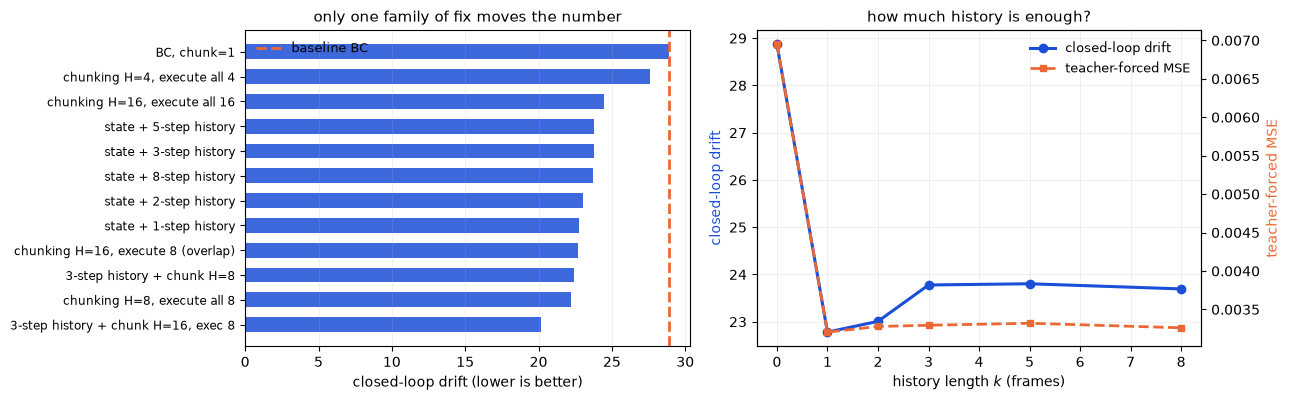

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.1))

ax = axes[0]
labels, tfs, cls = [], [], []
for k, v in results.items():
    if np.isnan(v["closed_loop"]):
        continue
    labels.append(k.replace(" (notebook 6 baseline)", "")); tfs.append(v["teacher_forced"]); cls.append(v["closed_loop"])
order = np.argsort(cls)
y = np.arange(len(order))
ax.barh(y, [cls[i] for i in order], color="#1b4fd8", alpha=0.85, height=0.6)
ax.axvline(base_cl, color="#eb6834", lw=2, ls="--", label="baseline BC")
ax.set_yticks(y); ax.set_yticklabels([labels[i] for i in order], fontsize=8.5)
ax.set_xlabel("closed-loop drift (lower is better)")
ax.set_title("only one family of fix moves the number", fontsize=11)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.22, lw=0.6, axis="x")

ax = axes[1]
ks = sorted(hist_nets)
d = [results[f"state + {k}-step history"]["closed_loop"] for k in ks]
t = [results[f"state + {k}-step history"]["teacher_forced"] for k in ks]
ax.plot([0] + ks, [base_cl] + d, lw=2.2, marker="o", ms=6, color="#1b4fd8", label="closed-loop drift")
ax.set_xlabel("history length $k$ (frames)"); ax.set_ylabel("closed-loop drift", color="#1b4fd8")
ax2 = ax.twinx()
ax2.plot([0] + ks, [base_tf] + t, lw=2.0, ls="--", marker="s", ms=5, color="#eb6834", label="teacher-forced MSE")
ax2.set_ylabel("teacher-forced MSE", color="#eb6834")
ax.set_title("how much history is enough?", fontsize=11)
lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], frameon=False, fontsize=9)
ax.grid(alpha=0.22, lw=0.6)
plt.tight_layout(); plt.show()

## 6. The real result: the two metrics disagree

Combining both fixes gives the best policy in the study: **3-step history +
chunk 16, execute 8 → drift 20.15, a 30% reduction** over baseline. The
mechanisms do compose, as expected once you know what each one does.

But the headline of this notebook is not the winner. It is this:

## 7. Summary — and the interview version

**Predictions made in advance, and how they held up:**

| Fix | Predicted | Observed | Verdict |
|---|---|---|---|
| Action chunking | no help | **−23% drift**, +113% offline loss | **wrong** |
| Vision (CNN) | no help, overfits | −7% offline, no overfit, unevaluable closed-loop | **wrong** |
| History (1-8 steps) | substantial help | **−54% offline**, −18-21% drift | right |
| *(not predicted)* | — | history + chunking: **−30% drift**, the best policy | — |

Two of three predictions failed, and the failure was productive. The chunking
prediction was wrong because I ruled out one mechanism (mode-disagreement) and
assumed that ruled out the fix, missing a second mechanism (feedback rate) that
works regardless of modality.

**The finding that outranks all of it:**

> Across twelve variants, `corr(offline MSE, closed-loop drift) = −0.25`. The
> best policy had 5.6x worse validation loss than the model validation loss
> preferred. Selecting on the offline metric costs 12% of the achievable
> improvement.

**Something you can say in an interview:**

> *"I compared action chunking, vision and history conditioning on a
> behavior-cloning policy for a real robot arm, evaluating each both offline and
> closed-loop in a simulator I'd system-identified against the hardware. The
> useful result was that the two metrics ranked the methods in conflicting
> orders — rank correlation about −0.25. Action chunking tripled the offline loss
> and cut closed-loop drift by 23%, because predicting an action chunk is a
> harder regression problem but executing one means you stop closing a feedback
> loop on stale state. I'd written my predictions down first and got two of three
> wrong, which is how I found the second mechanism."*

That answer shows measurement discipline, a mechanism-level explanation, and
willingness to report a failed prediction. Those are rarer than knowing the
method names.

### Exercises

1. **Put error bars on the headline.** Re-run the whole comparison with 5 seeds
   per variant and recompute the rank correlation with a bootstrap confidence
   interval. Twelve points and one seed is thin evidence for −0.25; find out
   whether the *rank disagreement at the top* survives, which is the claim that
   actually matters.
2. **Build the diffusion head, and show it winning.** Synthesise a multimodal
   dataset using notebook 2's exercise 3 (flip `shoulder_pan` on half the
   episodes), then implement a flow-matching action head — predict a velocity
   field from noise to action, conditioned on the observation — and beat the MSE
   policy *there*. This is the architecture behind π0 and GR00T.
3. **Separate chunking's two mechanisms.** Train with $H$ = 8 but execute only 1
   action before replanning. If chunking helps through *feedback rate*, this
   should lose most of the benefit; if it helps through a better-conditioned
   learning problem, it should keep it. One run distinguishes the two
   explanations.
4. **Velocity instead of history.** Replace the $k$-step stack with
   `[state, velocity]` — six extra numbers instead of $6k$. If it recovers the
   54% offline gain, what history supplies here is simply direction of travel,
   and you have a much cheaper fix.
5. **Does history fix the thing it was supposed to?** Re-run notebook 6's
   recurring-pose analysis using history features instead of bare states. The
   action gap at matched *histories* should be smaller than at matched *states*.
   That is the mechanism check that closes the loop on the diagnosis.